# Evolutionary Computation Practical Work — Part 5
## The Travelling Salesman Problem: What Should Crossover Preserve?

**Course:** Computational Intelligence, Master in Artificial Intelligence (CI-MAI)  
**Authors:** Fardin Ahmed & Sparsh Dubey
**Benchmark:** TSPLIB `ulysses22` (n = 22 cities, TSPLIB `GEO` distance metric, known global optimum L* = 7013)

---

## 1. Research Question

> **Do crossover operators that pass on the edges of the parents work better than those that pass on positions, and is the heritability of edges the reason?**

## 2. Hypotheses

### Hypothesis 1 — Edge Heritability

   - Edge Recombination (ER) is expected to achieve the highest dynamic edge heritability ($h_e$), followed by Order Crossover (OX) and Partially Mapped Crossover (PMX).
   - ER is expected to preserve more parental adjacencies because it explicitly uses edge information during recombination.

### Hypothesis 2 — Search Performance

   - Operators that preserve parental edge information (OX and ER) are expected to achieve shorter final tour lengths and higher observed global-optimum success rates than PMX.
   - This is because preserving useful city adjacencies can be more relevant to TSP tour quality than relying primarily on positional information.

###  What Would Refute the Hypotheses?

- **Hypothesis 1:** The hypothesis would be challenged if ER did not achieve higher edge heritability than OX and PMX, or if its measured edge heritability was not consistently higher across runs.

- **Hypothesis 2:** The hypothesis would be challenged if OX and ER did not achieve shorter final tour lengths or higher optimum success rates than PMX. A lack of statistically significant differences would provide insufficient evidence to support the expected performance advantage.

- **Mechanistic Explanation:** If higher edge heritability did not correspond to improved optimisation performance, this would indicate that edge preservation alone is insufficient to explain the differences between crossover operators.

## 3. Operators Compared

| Operator | Type | Preserved Property | Description |
|:---|:---|:---|:---|
| **PMX** | Crossover | Positional information and mapping | Partially Mapped Crossover (Goldberg & Lingle, 1985); uses positional correspondence and mapping to resolve conflicts between parents. |
| **OX** | Crossover | Relative Order | Order Crossover (Davis, 1985); copies a contiguous segment from one parent and preserves the relative ordering of remaining cities from the other parent. |
| **ER** | Crossover | Adjacency Edges | Edge Recombination Crossover (Whitley et al., 1989); builds an adjacency table from both parents and prioritises parental edges when constructing offspring. |



### 1. Environment Setup, Imports, and Global Configuration

We import the required scientific computing libraries (`numpy`, `scipy`, `pandas`), visualization tools (`matplotlib`), TSPLIB parser (`tsplib95`), and evolutionary algorithm framework (`deap`). We also configure the plotting style, define global experiment settings and operator labels, initialize random experiment parameters where applicable, and create directories for storing results and figures.


In [1]:
# Imports, Global Configuration, and Reproducibility Setup

import os
import sys
import time
import math
import random
import warnings

import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import mannwhitneyu, wilcoxon, rankdata
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import tsplib95
from deap import base, creator, tools, algorithms
from IPython.display import display, HTML

# Suppress non-critical runtime warnings
warnings.filterwarnings('ignore')

# Set publication-quality matplotlib style
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'legend.fontsize': 8.5,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.grid': True,
    'grid.alpha': 0.3,
})

# Operator palette and display labels
OPERATOR_ORDER = ["PMX", "OX", "ER", "NO-CX"]
OPERATOR_COLORS = {
    "PMX": "steelblue",
    "OX": "darkorange",
    "ER": "seagreen",
    "NO-CX": "red"
}
OPERATOR_LABELS = {
    "PMX":   "PMX (Position)",
    "OX":    "OX (Order/Edges)",
    "ER":    "ER (Edges)",
    "NO-CX": "NO-CX"
}

# Core problem constants
OPT_DIST = 7013  # Known global optimum for ulysses22 under TSPLIB GEO distance
RESULTS_DIR = "results"
FIGURES_DIR = "figures"
DATA_DIR = "data"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Environment setup successful.")
print(f"Operators: {OPERATOR_ORDER}")
print(f"Benchmark: ulysses22 (Optimum L* = {OPT_DIST})")


Environment setup successful.
Operators: ['PMX', 'OX', 'ER', 'NO-CX']
Benchmark: ulysses22 (Optimum L* = 7013)


## 2. TSPLIB Instance Loading and Distance Matrix

- **Problem Instance:** `ulysses22.tsp`, containing 22 geographical locations associated with Odysseus's voyage in Homer's *Odyssey*.
- **Distance Metric:** TSPLIB `GEO`, calculating geographical distances using latitude and longitude.
- **Distance Matrix:** An $n \times n$ integer matrix (`dist_matrix`) is precomputed to improve fitness evaluation efficiency.
- **Tour Representation:** Each tour is a 0-indexed permutation of city identifiers $[0, 1, \ldots, n-1]$.
- **Tour Evaluation:** Sums consecutive city distances, including the return to the starting city, to form a closed tour.


In [2]:
# TSPLIB Instance Loading & Tour Distance Evaluation


def load_tsplib_instance(filepath):
    """
    Load a TSPLIB .tsp file and precompute an n x n integer distance matrix.
    Returns:
        problem : tsplib95 Problem instance
        nodes   : list of node identifiers (1-indexed in TSPLIB)
        dist_matrix : 2D list of integer travel costs between 0-indexed cities
        coords  : list of (lon, lat) coordinates if available
    """
    problem = tsplib95.load(filepath)
    nodes = list(problem.get_nodes())
    n = len(nodes)
    dist_matrix = [
        [int(problem.get_weight(nodes[i], nodes[j])) for j in range(n)]
        for i in range(n)
    ]
    coords = None
    if hasattr(problem, "node_coords") and problem.node_coords:
        coords = [problem.node_coords[nodes[i]] for i in range(n)]
    return problem, nodes, dist_matrix, coords

def evaluate_tour(tour, dist_matrix):
    """
    Compute closed TSP tour length from precomputed distance matrix.
    Tour is represented as a permutation of 0-indexed city integers [0..n-1].
    """
    n = len(tour)
    total = dist_matrix[tour[-1]][tour[0]]
    for i in range(n - 1):
        total += dist_matrix[tour[i]][tour[i + 1]]
    return total

# Alias for compatibility
tour_length = evaluate_tour

# Load the benchmark problem
tsp_path = os.path.join(DATA_DIR, "ulysses22.tsp")
problem, nodes, dist_matrix, coords = load_tsplib_instance(tsp_path)
N_CITIES = len(nodes)

print(f"Loaded instance: {problem.name} ({problem.comment})")
print(f"Number of cities: {N_CITIES}")
print(f"Distance type: {problem.edge_weight_type}")
print(f"Verified optimum tour distance: {OPT_DIST}")


Loaded instance: ulysses22.tsp (Odyssey of Ulysses (Groetschel/Padberg))
Number of cities: 22
Distance type: GEO
Verified optimum tour distance: 7013


## 3. Permutation Crossover and Mutation Operators

Standard single-point and uniform crossovers can produce invalid permutations with duplicate or missing cities. Therefore, specialised operators are used to maintain valid TSP tours.

- **Order Crossover (OX):** Copies a segment from Parent 1 and fills remaining positions using Parent 2 while preserving relative city order.
- **Partially Mapped Crossover (PMX):** Copies a segment from Parent 1 and uses parent mapping to resolve conflicts and maintain a valid permutation.
- **Edge Recombination (ER):** Builds an undirected adjacency table from both parents, selects unvisited neighbours using the least-degree heuristic and prioritises shared parental edges.
- **Inversion Mutation:** Reverses a randomly selected segment while maintaining a valid permutation.

**Experimental Configuration:** PMX, OX and ER are compared using the same inversion mutation probability.


In [3]:
# Crossover and Mutation Operators


def cx_order(ind1, ind2):
    """
    Order Crossover (OX) — Davis (1985).
    Preserves relative city ordering and contiguous sub-tour segments.
    """
    size = len(ind1)
    a, b = random.sample(range(size), 2)
    if a > b:
        a, b = b, a
    
    holes1, holes2 = [True] * size, [True] * size
    for i in range(size):
        if i < a or i > b:
            holes1[ind2[i]] = False
            holes2[ind1[i]] = False
            
    temp1, temp2 = list(ind1), list(ind2)
    k1, k2 = b + 1, b + 1
    for i in range(size):
        idx = (i + b + 1) % size
        if not holes1[temp1[idx]]:
            ind1[k1 % size] = temp1[idx]
            k1 += 1
        if not holes2[temp2[idx]]:
            ind2[k2 % size] = temp2[idx]
            k2 += 1
            
    for i in range(a, b + 1):
        ind1[i] = temp2[i]
        ind2[i] = temp1[i]
        
    return ind1, ind2

def cx_pmx(ind1, ind2):
    """
    Partially Mapped Crossover (PMX) — Goldberg & Lingle (1985).
    Preserves absolute city positions by mapping conflicting entries.
    """
    size = len(ind1)
    p1, p2 = [0] * size, [0] * size
    for i in range(size):
        p1[ind1[i]] = i
        p2[ind2[i]] = i
        
    cxpoint1 = random.randint(0, size)
    cxpoint2 = random.randint(0, size - 1)
    if cxpoint2 >= cxpoint1:
        cxpoint2 += 1
    else:
        cxpoint1, cxpoint2 = cxpoint2, cxpoint1
        
    for i in range(cxpoint1, cxpoint2):
        val1 = ind1[i]
        val2 = ind2[i]
        pos1 = p1[val2]
        pos2 = p2[val1]
        ind1[i], ind1[pos1] = val2, val1
        ind2[i], ind2[pos2] = val1, val2
        p1[val1], p1[val2] = pos1, i
        p2[val1], p2[val2] = i, pos2
        
    return ind1, ind2

def _er_single(p1, p2, start_city):
    """
    Construct a single offspring via Edge Recombination (Whitley et al., 1989).
    """
    size = len(p1)
    adj = [[] for _ in range(size)]
    comm_a = [-1] * size
    comm_b = [-1] * size
    
    # Register parent 1 edges
    for i in range(size):
        u = p1[i]
        adj[u].append(p1[i - 1])
        adj[u].append(p1[(i + 1) % size])
        
    # Register parent 2 edges and track common edges
    for i in range(size):
        u = p2[i]
        u_adj = adj[u]
        for nb in (p2[i - 1], p2[(i + 1) % size]):
            if nb in u_adj:
                if comm_a[u] == -1:
                    comm_a[u] = nb
                else:
                    comm_b[u] = nb
            else:
                u_adj.append(nb)
                
    visited = [False] * size
    deg = [len(adj[u]) for u in range(size)]
    child = [0] * size
    child[0] = start_city
    visited[start_city] = True
    for nb in adj[start_city]:
        deg[nb] -= 1
        
    curr = start_city
    randrange = random.randrange
    
    for step in range(1, size):
        best_nb = -1
        # Attempt 1: search neighbors; Attempt 2: reverse prefix if stuck
        for attempt in range(2):
            min_d = 99
            best_is_comm = False
            ties = 0
            ca = comm_a[curr]
            cb = comm_b[curr]
            for nb in adj[curr]:
                if not visited[nb]:
                    d = deg[nb]
                    is_c = (nb == ca or nb == cb)
                    if d < min_d or (d == min_d and is_c and not best_is_comm):
                        min_d = d
                        best_nb = nb
                        best_is_comm = is_c
                        ties = 1
                    elif d == min_d and is_c == best_is_comm:
                        ties += 1
                        if randrange(ties) == 0:
                            best_nb = nb
            if best_nb != -1 or attempt == 1 or step <= 1:
                break
            # Reverse prefix to reopen path from other end
            child[:step] = child[:step][::-1]
            curr = child[step - 1]
            
        # Fallback if no neighbor available
        if best_nb == -1:
            rem = size - step
            k = randrange(rem)
            for u in range(size):
                if not visited[u]:
                    if k == 0:
                        best_nb = u
                        break
                    k -= 1
                    
        child[step] = best_nb
        visited[best_nb] = True
        for nb in adj[best_nb]:
            deg[nb] -= 1
        curr = best_nb
        
    return child

def cx_er(ind1, ind2):
    """
    Edge Recombination Crossover (ER) — Whitley et al. (1989).
    Preserves edge adjacencies from both parents.
    """
    size = len(ind1)
    p1, p2 = list(ind1), list(ind2)
    c1 = _er_single(p1, p2, p1[random.randrange(size)])
    c2 = _er_single(p2, p1, p2[random.randrange(size)])
    ind1[:] = c1
    ind2[:] = c2
    return ind1, ind2


def mut_inversion(individual):
    """
    Inversion Mutation (SIM): Reverses a randomly selected sub-path.
    """
    n = len(individual)
    a, b = random.sample(range(n), 2)
    if a > b:
        a, b = b, a
    individual[a:b + 1] = individual[a:b + 1][::-1]
    return individual,

def two_opt_first_improvement(tour, dist_matrix):
    """
    First-improvement 2-opt local search move.
    """
    n = len(tour)
    for i in range(n - 1):
        u1, v1 = tour[i], tour[i + 1]
        d1 = dist_matrix[u1][v1]
        for j in range(i + 2, n if i > 0 else n - 1):
            u2, v2 = tour[j], tour[(j + 1) % n]
            d_curr = d1 + dist_matrix[u2][v2]
            d_new = dist_matrix[u1][u2] + dist_matrix[v1][v2]
            if d_new < d_curr:
                tour[i + 1:j + 1] = tour[i + 1:j + 1][::-1]
                return True
    return False

# Mapping from operator name to crossover function
CROSSOVER_FNS = {
    "OX":  cx_order,
    "PMX": cx_pmx,
    "ER":  cx_er,
}

print("Crossover operators registered: OX, PMX, ER.")
print("Mutation operator: Inversion Mutation (SIM).")


Crossover operators registered: OX, PMX, ER.
Mutation operator: Inversion Mutation (SIM).


## 4. Heritability and Population Diversity Metrics

We use two measurements to examine parental edge preservation and population variation.

### 4.1 Edge Heritability ($h_e$)

Measures the proportion of offspring edges inherited from either parent.

$$
h_e = \frac{|E(C) \cap (E(P_1) \cup E(P_2))|}{n}
$$

   - $E(C)$: Child's undirected edges.
   - $E(P_1)$ and $E(P_2)$: Parent's undirected edges.
   - $n$: Number of cities.
   - Measured immediately after crossover and before mutation.

### 4.2 Population Edge Diversity ($D_e(t)$)

Measures the number of distinct edges across the population, normalized by the number of cities.

$$
D_e(t) = \frac{\left|\bigcup_{I \in \mathcal{P}_t} E(I)\right|}{n}
$$

   - $\mathcal{P}_t$: Population at generation $t$.
   - $E(I)$: Undirected edges in an individual tour.
   - $n$: Number of cities.

Higher values indicate greater variation in population edge combinations.

### 4.3 Purpose

   - **Edge heritability:** Measures how effectively crossover preserves parental edges.
   - **Edge diversity:** Tracks how population variation changes during evolution.

Together, these measurements help investigate the relationship between edge preservation, population diversity and optimisation performance.


In [4]:
# Quantitative Metrics (Heritability and Diversity)


def tour_edges(tour):
    """Return the set of undirected edges in a closed tour."""
    n = len(tour)
    return frozenset(
        tuple(sorted((tour[i], tour[(i + 1) % n])))
        for i in range(n)
    )

def compute_edge_heritability(child, p1, p2):
    """
    Fraction of child edges that appear in at least one parent.
    h_e = |E(child) ∩ (E(p1) ∪ E(p2))| / n
    """
    n = len(child)
    c_edges = tour_edges(child)
    p_edges = tour_edges(p1) | tour_edges(p2)
    return len(c_edges & p_edges) / n


def compute_population_edge_diversity(population):
    """
    Normalized edge diversity: total distinct undirected edges in population divided by n.
    D_e(t) = |bigcup_{I in pop} E(I)| / n. Minimum is 1.0 (all individuals identical).
    """
    if not population:
        return 0.0
    n = len(population[0])
    union_edges = set()
    for ind in population:
        union_edges.update(tour_edges(ind))
    return len(union_edges) / n

print("Metrics defined: edge heritability, edge diversity.")


Metrics defined: edge heritability, edge diversity.



## 5. DEAP Genetic Algorithm Engine

We implement a generational Genetic Algorithm using the DEAP framework with the following configuration:

### 5.1 GA Configuration

   - **Representation:** Permutations of $n = 22$ cities.
   - **Population Size:** $N = 200$.
   - **Generations:** $G = 1{,}000$.
   - **Selection:** Tournament selection ($k = 3$).
   - **Crossover Probability:** $p_c = 0.9$.
   - **Mutation:** Inversion mutation ($p_m = 0.2$).
   - **Elitism:** Best individual copied into the next generation.
   - **Hall of Fame:** `HallOfFame(1)` tracks the best solution.

### 5.2 Dynamic Measurements

   - Edge heritability and population edge diversity are recorded every 10 generations.
   - Edge heritability is measured immediately after crossover and before mutation.

### 5.3 Reproducibility

   - Python and NumPy random seeds are reset for each run.
   - The same 30 seeds (2000–2029) are used across all three operators, ensuring identical initial populations for corresponding runs.


In [5]:
# DEAP Evolutionary Algorithm Engine


# DEAP class setup with idempotency guard
if not hasattr(creator, "FitnessMin") or creator.FitnessMin.weights != (-1.0,):
    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))

if not hasattr(creator, "Individual"):
    creator.create("Individual", list, fitness=creator.FitnessMin)


def run_single_ga(operator_name, seed, dist_matrix, n_cities,
                  pop_size=200, n_gen=1000, cx_pb=0.9, mut_pb=0.2,
                  record_interval=10):
    """
    Execute a single GA run on ulysses22.

    NO-CX is the baseline control and disables crossover.
    """

    random.seed(seed)
    np.random.seed(seed)

    toolbox = base.Toolbox()

    toolbox.register("indices", random.sample, range(n_cities), n_cities)
    toolbox.register("individual", tools.initIterate, creator.Individual, toolbox.indices)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("evaluate", lambda ind: (evaluate_tour(ind, dist_matrix),))
    toolbox.register("select", tools.selTournament, tournsize=3)
    toolbox.register("mutate", mut_inversion)

    # Disable crossover for the baseline control
    actual_cx_pb = 0.0 if operator_name == "NO-CX" else cx_pb

    if operator_name != "NO-CX":
        toolbox.register("mate", CROSSOVER_FNS[operator_name])

    # Initialise population
    pop = toolbox.population(n=pop_size)

    for ind in pop:
        ind.fitness.values = toolbox.evaluate(ind)

    hof = tools.HallOfFame(1)
    hof.update(pop)

    history = []
    he_acc = []
    first_opt_gen = None

    for gen in range(1, n_gen + 1):

        # Selection
        offspring = toolbox.select(pop, len(pop))
        offspring = list(map(toolbox.clone, offspring))

        # Apply crossover (not used by NO-CX)
        if operator_name != "NO-CX":
            for i in range(0, len(offspring) - 1, 2):

                if random.random() < actual_cx_pb:

                    p1 = list(offspring[i])
                    p2 = list(offspring[i + 1])

                    toolbox.mate(offspring[i], offspring[i + 1])

                    # Measure edge heritability before mutation
                    he1 = compute_edge_heritability(offspring[i], p1, p2)
                    he2 = compute_edge_heritability(offspring[i + 1], p1, p2)

                    he_acc.append(0.5 * (he1 + he2))

                    offspring[i].fitness.values = toolbox.evaluate(offspring[i])
                    offspring[i + 1].fitness.values = toolbox.evaluate(offspring[i + 1])

        # Apply inversion mutation
        for ind in offspring:

            if random.random() < mut_pb:
                toolbox.mutate(ind)
                del ind.fitness.values

        # Re-evaluate individuals with invalid fitness
        invalid = [ind for ind in offspring if not ind.fitness.valid]

        for ind in invalid:
            ind.fitness.values = toolbox.evaluate(ind)

        # Elitism: preserve the best individual from the current population
        best_of_pop = tools.selBest(pop, 1)[0]
        offspring[0] = toolbox.clone(best_of_pop)

        pop[:] = offspring
        hof.update(pop)

        best_len = hof[0].fitness.values[0]

        if first_opt_gen is None and best_len <= OPT_DIST:
            first_opt_gen = gen

        # Record measurements
        if gen % record_interval == 0 or gen == n_gen:

            mean_len = float(np.mean([ind.fitness.values[0] for ind in pop]))

            mean_he = float(np.mean(he_acc[-50:])) if he_acc else np.nan

            edge_div = compute_population_edge_diversity(pop)

            history.append({
                "gen": gen,
                "best_length": best_len,
                "mean_length": mean_len,
                "edge_heritability": mean_he,
                "edge_diversity": edge_div,
            })

    final_he = float(np.mean(he_acc)) if he_acc else np.nan
    final_div = compute_population_edge_diversity(pop)

    return {
        "final_best": int(hof[0].fitness.values[0]),
        "mean_dyn_he": final_he,
        "final_edge_diversity": final_div,
        "reached_opt": int(hof[0].fitness.values[0]) <= OPT_DIST,
        "first_opt_gen": first_opt_gen if first_opt_gen is not None else n_gen,
        "best_tour": list(hof[0]),
        "history": history,
    }


def run_experiment(operator_names, seeds, dist_matrix, n_cities, label=""):
    """
    Run all configurations across specified random seeds.
    """

    run_rows, hist_rows = [], []

    total = len(operator_names) * len(seeds)
    done = 0

    for op in operator_names:

        for seed in seeds:

            done += 1

            if done % 10 == 0 or done == total:
                print(
                    f"  {label} [{done}/{total}]: {op} (seed={seed})",
                    end="\r"
                )

            res = run_single_ga(op, seed, dist_matrix, n_cities)

            run_rows.append({
                "operator": op,
                "seed": seed,
                "final_best": res["final_best"],
                "gap_pct": round((res["final_best"] / OPT_DIST - 1) * 100, 4),
                "reached_opt": res["reached_opt"],
                "first_opt_gen": res["first_opt_gen"],
                "censored": not res["reached_opt"],
                "mean_dyn_he": res["mean_dyn_he"],
                "final_edge_diversity": res["final_edge_diversity"],
            })

            for h in res["history"]:
                hist_rows.append({
                    "operator": op,
                    "seed": seed,
                    **h
                })

    print()

    return pd.DataFrame(run_rows), pd.DataFrame(hist_rows)


print("GA evolutionary engine compiled.")


GA evolutionary engine compiled.


### 6. Experiment 1A: Pilot Study ($R=10$ Runs) & Sample Size Justification

We first conduct a pilot study of $R = 10$ runs per operator (seeds 1000–1009) to gauge run-to-run variance, estimate effect sizes, and statistically justify the sample size of the full study.

**Run Count Justification:** 

The pilot results showed noticeable differences in both mean performance and run-to-run variability. PMX had the highest standard deviation (63.44), while OX and ER had lower standard deviations of 40.41 and 38.30, respectively. The observed optimum success rates also differed, ranging from 30% for PMX to 80% for ER.

Based on these preliminary observations, 30 matched seeds were selected for the main experiment to provide a larger sample for paired comparisons and a more reliable assessment of variability. This was a practical sample-size decision informed by the pilot results, rather than the outcome of a formal statistical power analysis.

In [6]:
# Pilot Study (R = 10 Runs per Operator, Seeds 1000–1009)

PILOT_CSV = os.path.join(RESULTS_DIR, "ulysses22_pilot10_summary.csv")
PILOT_SEEDS = list(range(1000, 1010))

if os.path.exists(PILOT_CSV):
    df_pilot = pd.read_csv(PILOT_CSV)
    print("Loaded pilot study results from CSV.")
else:
    print("Executing pilot study (3 operators x 10 runs = 30 GA runs) ...")
    df_pilot_runs, _ = run_experiment(OPERATOR_ORDER, PILOT_SEEDS, dist_matrix, N_CITIES, label="Pilot")
    df_pilot = df_pilot_runs.groupby("operator").agg(
        n_runs=("final_best", "count"),
        median=("final_best", "median"),
        iqr=("final_best", lambda x: x.quantile(0.75) - x.quantile(0.25)),
        mean=("final_best", "mean"),
        sd=("final_best", "std"),
        min=("final_best", "min"),
        max=("final_best", "max"),
        opt_rate_pct=("reached_opt", lambda x: 100 * x.mean()),
        med_first_opt_gen=("first_opt_gen", "median"),
        censored_pct=("censored", lambda x: 100 * x.mean()),
    ).reset_index()
    # Reorder according to OPERATOR_ORDER
    df_pilot["sort_key"] = df_pilot["operator"].map({op: i for i, op in enumerate(OPERATOR_ORDER)})
    df_pilot = df_pilot.sort_values("sort_key").drop(columns=["sort_key"])
    df_pilot.to_csv(PILOT_CSV, index=False)
    print("Saved pilot summary to", PILOT_CSV)

print("\nTABLE 2 — Pilot Study Summary (R = 10 Runs, Seeds 1000–1009):")
display(df_pilot[["operator", "n_runs", "median", "iqr", "mean", "sd", "min", "max", "opt_rate_pct"]].round(2))


Loaded pilot study results from CSV.

TABLE 2 — Pilot Study Summary (R = 10 Runs, Seeds 1000–1009):


,operator,n_runs,median,iqr,mean,sd,min,max,opt_rate_pct
0,PMX,10,7091.5,86.75,7089.2,63.44,7013,7190,30.0
1,OX,10,7013.0,59.25,7038.0,40.41,7013,7105,70.0
2,ER,10,7013.0,0.00,7031.0,38.30,7013,7114,80.0


### 7. Experiment 1B: Full Core Experiment (R = 30 Runs, G = 1,000 Generations)

The initial core experiment compares three crossover operators: PMX, OX, and ER, across 30 matched random seeds (2000–2029). Each run uses a population of 200 individuals and runs for 1,000 generations.

All three operators use identical initial populations for corresponding seeds, enabling paired statistical comparisons using the Wilcoxon signed-rank test.

This initial experiment consists of 90 GA executions in total (30 runs per crossover operator).

A NO-CX baseline control is subsequently added in Experiment 1C, using the same random seeds and GA settings but with crossover disabled. This brings the complete experiment to 120 GA executions across four configurations.

In [7]:
# Full Core Experiment (R = 30 Runs per Operator, Seeds 2000-2029)


RUNS_CSV    = os.path.join(RESULTS_DIR, "ulysses22_runs.csv")
HISTORY_CSV = os.path.join(RESULTS_DIR, "ulysses22_history.csv")
SUMMARY_CSV = os.path.join(RESULTS_DIR, "ulysses22_summary.csv")
MAIN_SEEDS  = list(range(2000,2030))

if os.path.exists(RUNS_CSV) and os.path.exists(HISTORY_CSV):
    df_runs = pd.read_csv(RUNS_CSV)
    df_history = pd.read_csv(HISTORY_CSV)
    print(f"Loaded core experiment data: {len(df_runs)} runs, {len(df_history)} history checkpoints.")
else:
    print("Executing full experiment (3 operators x 30 runs = 90 GA runs) ...")
    df_runs, df_history = run_experiment(OPERATOR_ORDER, MAIN_SEEDS, dist_matrix, N_CITIES, label="Core")
    df_runs.to_csv(RUNS_CSV, index=False)
    df_history.to_csv(HISTORY_CSV, index=False)
    print("Saved runs and history checkpoints.")

def summarise_runs(df):
    
    rows = []
    for op in OPERATOR_ORDER:
        sub = df[df["operator"] == op]
        bests = sub["final_best"]
        rows.append({
            "operator": op,
            "n_runs": len(bests),
            "median": float(bests.median()),
            "iqr": float(bests.quantile(0.75) - bests.quantile(0.25)),
            "mean": float(bests.mean()),
            "sd": float(bests.std()),
            "min": int(bests.min()),
            "max": int(bests.max()),
            "opt_rate_pct": float(100 * sub["reached_opt"].mean()),
            "med_first_opt_gen": float(sub["first_opt_gen"].median()),
            "censored_pct": float(100 * sub["censored"].mean()),
            "dyn_he_mean": float(sub["mean_dyn_he"].mean()),
            "final_edge_div_mean": float(sub["final_edge_diversity"].mean()),
        })
    return pd.DataFrame(rows)

if os.path.exists(SUMMARY_CSV):
    df_summary = pd.read_csv(SUMMARY_CSV)
    print("Loaded summary metrics from CSV.")
else:
    df_summary = summarise_runs(df_runs)
    df_summary.to_csv(SUMMARY_CSV, index=False)
    print("Saved summary metrics to", SUMMARY_CSV)

print("\nTABLE 3 — Main Experiment Summary on ulysses22 (R = 30 Runs, G = 1,000):")
display(df_summary[["operator", "median", "iqr", "mean", "sd", "min", "max", "opt_rate_pct", "dyn_he_mean"]].round(2))


Loaded core experiment data: 120 runs, 12000 history checkpoints.
Loaded summary metrics from CSV.

TABLE 3 — Main Experiment Summary on ulysses22 (R = 30 Runs, G = 1,000):


,operator,median,iqr,mean,sd,min,max,opt_rate_pct,dyn_he_mean
0,PMX,7107.0,107.00,7113.40,72.89,7013,7241,23.33,0.98
1,OX,7013.0,95.50,7052.77,51.77,7013,7163,60.00,0.98
2,ER,7013.0,79.00,7051.43,46.48,7013,7150,56.67,1.00
3,NO-CX,7089.5,132.25,7090.27,75.50,7013,7241,40.00,NaN


In [8]:

# NO-CX Baseline Experiment (30 Runs, Seeds 2000-2029)


EXPERIMENT_ORDER = ["PMX", "OX", "ER", "NO-CX"]

# Load the existing core experiment results.
df_runs = pd.read_csv(RUNS_CSV)
df_history = pd.read_csv(HISTORY_CSV)

# Verify that the original 90 runs are present.
for op in ["PMX", "OX", "ER"]:
    existing_seeds = set(
        df_runs.loc[df_runs["operator"] == op, "seed"]
    )
    if existing_seeds != set(MAIN_SEEDS):
        raise ValueError(
            f"{op} results are incomplete or incorrect. "
            f"Expected seeds 2000-2029, found {len(existing_seeds)} seeds."
        )

print("Original PMX, OX and ER results verified.")

# Identify missing NO-CX baseline runs.
existing_nocx_seeds = set(
    df_runs.loc[df_runs["operator"] == "NO-CX", "seed"]
)

missing_nocx_seeds = [
    seed for seed in MAIN_SEEDS
    if seed not in existing_nocx_seeds
]

print(f"Existing NO-CX runs: {len(existing_nocx_seeds)}")
print(f"Missing NO-CX runs: {len(missing_nocx_seeds)}")

# Execute only the missing baseline runs.
if missing_nocx_seeds:
    print("\nRunning NO-CX baseline experiments...")

    df_nocx_runs, df_nocx_history = run_experiment(
        ["NO-CX"],
        missing_nocx_seeds,
        dist_matrix,
        N_CITIES,
        label="NO-CX Baseline"
    )

    df_runs = pd.concat(
        [df_runs, df_nocx_runs],
        ignore_index=True
    )

    df_history = pd.concat(
        [df_history, df_nocx_history],
        ignore_index=True
    )

else:
    print("All NO-CX baseline runs already exist.")

# Verify all four configurations.
for op in EXPERIMENT_ORDER:
    sub = df_runs[df_runs["operator"] == op]
    seeds = set(sub["seed"])

    if len(sub) != 30 or seeds != set(MAIN_SEEDS):
        raise ValueError(
            f"{op} verification failed: "
            f"{len(sub)} runs and {len(seeds)} unique seeds."
        )

# Save the combined experiment results.
df_runs.to_csv(RUNS_CSV, index=False)
df_history.to_csv(HISTORY_CSV, index=False)

# Generate a fresh summary for all four configurations.
def summarise_all_runs(df):
    rows = []

    for op in EXPERIMENT_ORDER:
        sub = df[df["operator"] == op]
        bests = sub["final_best"]

        rows.append({
            "operator": op,
            "n_runs": len(bests),
            "median": float(bests.median()),
            "iqr": float(bests.quantile(0.75) - bests.quantile(0.25)),
            "mean": float(bests.mean()),
            "sd": float(bests.std()),
            "min": int(bests.min()),
            "max": int(bests.max()),
            "opt_rate_pct": float(100 * sub["reached_opt"].mean()),
            "med_first_opt_gen": float(sub["first_opt_gen"].median()),
            "censored_pct": float(100 * sub["censored"].mean()),
            "dyn_he_mean": float(sub["mean_dyn_he"].mean()),
            "final_edge_div_mean": float(sub["final_edge_diversity"].mean()),
        })

    return pd.DataFrame(rows)


df_summary = summarise_all_runs(df_runs)
df_summary.to_csv(SUMMARY_CSV, index=False)

# Final verification and display.
print("\nEXPERIMENT COMPLETED")
print("\nRuns per configuration:")
print(df_runs["operator"].value_counts().reindex(EXPERIMENT_ORDER))

print(f"\nTotal GA executions: {len(df_runs)}")
print(f"Total history records: {len(df_history)}")

print("\nTABLE 3 — Main Experiment Summary on ulysses22")
display(
    df_summary[
        [
            "operator", "n_runs", "median", "iqr", "mean", "sd",
            "min", "max", "opt_rate_pct", "med_first_opt_gen",
            "censored_pct", "dyn_he_mean", "final_edge_div_mean"
        ]
    ].round(2)
)

print("\nUpdated results saved to:")
print(RUNS_CSV)
print(HISTORY_CSV)
print(SUMMARY_CSV)


Original PMX, OX and ER results verified.
Existing NO-CX runs: 30
Missing NO-CX runs: 0
All NO-CX baseline runs already exist.

EXPERIMENT COMPLETED

Runs per configuration:
operator
PMX      30
OX       30
ER       30
NO-CX    30
Name: count, dtype: int64

Total GA executions: 120
Total history records: 12000

TABLE 3 — Main Experiment Summary on ulysses22


,operator,n_runs,median,iqr,mean,sd,min,max,opt_rate_pct,med_first_opt_gen,censored_pct,dyn_he_mean,final_edge_div_mean
0,PMX,30,7107.0,107.00,7113.40,72.89,7013,7241,23.33,1000.0,76.67,0.98,4.12
1,OX,30,7013.0,95.50,7052.77,51.77,7013,7163,60.00,221.5,40.00,0.98,4.36
2,ER,30,7013.0,79.00,7051.43,46.48,7013,7150,56.67,52.5,43.33,1.00,3.97
3,NO-CX,30,7089.5,132.25,7090.27,75.50,7013,7241,40.00,1000.0,60.00,NaN,4.03



Updated results saved to:
results\ulysses22_runs.csv
results\ulysses22_history.csv
results\ulysses22_summary.csv


### 8. Statistical Analysis: Non-Parametric Tests & Effect Sizes

Since all four experimental configurations use identical initial populations for corresponding random seeds (2000–2029), the experiment follows a paired design. The 30 seeds are treated as blocks in the statistical analysis.

1. **Friedman Test:** Used as the overall non-parametric test to determine whether there are statistically significant differences between PMX, OX, ER, and NO-CX across matched seeds.

2. **Pairwise Wilcoxon Signed-Rank Tests:** If the Friedman test is statistically significant, six pairwise comparisons are performed:
   - PMX vs OX
   - PMX vs ER
   - PMX vs NO-CX
   - OX vs ER
   - OX vs NO-CX
   - ER vs NO-CX

   Holm correction is applied across the six comparisons to control the family-wise error rate at α = 0.05.

3. **Matched-Pairs Rank-Biserial Correlation:** Reported as the primary effect size for pairwise comparisons, indicating the magnitude and direction of differences between configurations.

4. **Hodges–Lehmann Estimate:** The estimated median paired difference in final tour length is reported with its 95% confidence interval.

5. **Win Fraction:** The proportion of non-tied matched seeds in which one configuration produces a shorter final tour than the other is reported as an intuitive measure of comparative performance. Wins, losses, and ties are also reported separately.

6. **Handling Ties:** Zero paired differences are excluded from the Wilcoxon signed-rank calculation using the Wilcoxon convention. The number of zero differences is reported for transparency.

The NO-CX configuration serves as a baseline control, allowing the contribution of crossover to be assessed by comparing each crossover configuration against a GA that uses selection, inversion mutation, and elitism without crossover.


In [9]:
# Statistical Analysis (4 Configurations, 30 Matched Seeds)

import numpy as np
import pandas as pd
from itertools import combinations
from scipy import stats

# Load the complete run-level results.
df_runs = pd.read_csv(RUNS_CSV)

EXPERIMENT_ORDER = ["PMX", "OX", "ER", "NO-CX"]
MAIN_SEEDS = list(range(2000, 2030))

# -------------------------------------------------------------------------
# 1. Verify the experimental data
# -------------------------------------------------------------------------

if df_runs.duplicated(subset=["operator", "seed"]).any():
    raise ValueError("Duplicate operator/seed combinations found.")

results = df_runs.pivot(
    index="seed",
    columns="operator",
    values="final_best"
)

results = results.reindex(
    index=MAIN_SEEDS,
    columns=EXPERIMENT_ORDER
)

if results.isna().any().any():
    raise ValueError(
        "Missing results detected. Each configuration must have "
        "30 results with matching seeds."
    )

print("DATA VERIFICATION")
print(f"Matched seeds: {len(results)}")
print(f"Configurations: {len(EXPERIMENT_ORDER)}")
print(f"Total observations: {results.size}")

# -------------------------------------------------------------------------
# 2. Friedman test
# -------------------------------------------------------------------------

friedman_result = stats.friedmanchisquare(
    *[results[op].values for op in EXPERIMENT_ORDER]
)

print("\nFRIEDMAN TEST")
print(f"Chi-square statistic: {friedman_result.statistic:.4f}")
print(f"Degrees of freedom: {len(EXPERIMENT_ORDER) - 1}")
print(f"P-value: {friedman_result.pvalue:.6f}")

if friedman_result.pvalue < 0.05:
    print("Result: Significant differences detected between configurations.")
else:
    print("Result: No statistically significant differences detected.")

# -------------------------------------------------------------------------
# 3. Pairwise Wilcoxon signed-rank tests
# -------------------------------------------------------------------------

def holm_adjust(p_values):
    """Apply Holm's step-down correction."""
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)

    order = np.argsort(p_values)
    adjusted = np.empty(m)

    running_max = 0.0

    for rank, idx in enumerate(order):
        value = (m - rank) * p_values[idx]
        running_max = max(running_max, value)
        adjusted[idx] = min(running_max, 1.0)

    return adjusted


def hodges_lehmann(differences):
    """
    Calculate the paired Hodges-Lehmann estimate.
    This is the median of all Walsh averages.
    """
    d = np.asarray(differences, dtype=float)

    walsh = (
        d[:, None] + d[None, :]
    ) / 2.0

    return float(np.median(walsh[np.triu_indices(len(d))]))


def bootstrap_hl_ci(differences, n_boot=5000, seed=42):
    """
    Approximate 95% percentile bootstrap CI for the
    paired Hodges-Lehmann estimate.
    """
    d = np.asarray(differences, dtype=float)
    rng = np.random.default_rng(seed)

    n = len(d)
    upper_indices = np.triu_indices(n)

    estimates = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(d, size=n, replace=True)

        walsh = (
            sample[:, None] + sample[None, :]
        ) / 2.0

        estimates[i] = np.median(walsh[upper_indices])

    lower, upper = np.percentile(estimates, [2.5, 97.5])

    return float(lower), float(upper)


pairwise_rows = []

for op_a, op_b in combinations(EXPERIMENT_ORDER, 2):

    # Positive difference means op_a has a higher (worse) tour cost.
    differences = (
        results[op_a] - results[op_b]
    ).to_numpy(dtype=float)

    nonzero = differences[differences != 0]
    wins_a = int(np.sum(differences < 0))
    losses_a = int(np.sum(differences > 0))
    ties = int(np.sum(differences == 0))

    # Hodges-Lehmann estimate and bootstrap confidence interval.
    hl = hodges_lehmann(differences)
    ci_low, ci_high = bootstrap_hl_ci(
        differences,
        seed=42
    )

    # Matched-pairs rank-biserial correlation.
    if len(nonzero) == 0:
        rank_biserial = 0.0
        wilcoxon_stat = 0.0
        p_value = 1.0

    else:
        ranks = stats.rankdata(np.abs(nonzero))

        positive_rank_sum = np.sum(ranks[nonzero > 0])
        negative_rank_sum = np.sum(ranks[nonzero < 0])

        rank_biserial = (
            positive_rank_sum - negative_rank_sum
        ) / np.sum(ranks)

        # Wilcoxon excludes zero differences.
        wilcoxon_result = stats.wilcoxon(
            differences,
            zero_method="wilcox",
            alternative="two-sided",
            method="auto"
        )

        wilcoxon_stat = float(wilcoxon_result.statistic)
        p_value = float(wilcoxon_result.pvalue)

    pairwise_rows.append({
        "comparison": f"{op_a} vs {op_b}",
        "HL_difference": hl,
        "CI_95_low": ci_low,
        "CI_95_high": ci_high,
        "rank_biserial": rank_biserial,
        "wins_A": wins_a,
        "losses_A": losses_a,
        "ties": ties,
        "wilcoxon_statistic": wilcoxon_stat,
        "p_raw": p_value,
        "win_fraction_A": (
        wins_a / (wins_a + losses_a)
        if (wins_a + losses_a) > 0 else np.nan
        )
    })


# -------------------------------------------------------------------------
# 4. Holm correction for six pairwise comparisons
# -------------------------------------------------------------------------

pairwise_df = pd.DataFrame(pairwise_rows)

pairwise_df["p_holm"] = holm_adjust(
    pairwise_df["p_raw"].values
)

pairwise_df["significant"] = (
    pairwise_df["p_holm"] < 0.05
)

print("\nPAIRWISE WILCOXON SIGNED-RANK TESTS")
print("Zero differences are excluded from the Wilcoxon test.")
print("Positive HL differences mean configuration A has worse tour costs.")
print("Positive rank-biserial values mean configuration A tends to be worse.")

display(
    pairwise_df.round(4)
)

# -------------------------------------------------------------------------
# 5. Save statistical results
# -------------------------------------------------------------------------

FRIEDMAN_CSV = os.path.join(
    RESULTS_DIR,
    "ulysses22_friedman_test.csv"
)

PAIRWISE_CSV = os.path.join(
    RESULTS_DIR,
    "ulysses22_pairwise_tests.csv"
)

friedman_df = pd.DataFrame([{
    "test": "Friedman",
    "configurations": len(EXPERIMENT_ORDER),
    "matched_seeds": len(results),
    "chi_square": float(friedman_result.statistic),
    "degrees_of_freedom": len(EXPERIMENT_ORDER) - 1,
    "p_value": float(friedman_result.pvalue)
}])

friedman_df.to_csv(FRIEDMAN_CSV, index=False)
pairwise_df.to_csv(PAIRWISE_CSV, index=False)

print("\nStatistical analysis saved:")
print(FRIEDMAN_CSV)
print(PAIRWISE_CSV)


DATA VERIFICATION
Matched seeds: 30
Configurations: 4
Total observations: 120

FRIEDMAN TEST
Chi-square statistic: 18.3024
Degrees of freedom: 3
P-value: 0.000381
Result: Significant differences detected between configurations.

PAIRWISE WILCOXON SIGNED-RANK TESTS
Zero differences are excluded from the Wilcoxon test.
Positive HL differences mean configuration A has worse tour costs.
Positive rank-biserial values mean configuration A tends to be worse.


,comparison,HL_difference,CI_95_low,CI_95_high,rank_biserial,wins_A,losses_A,ties,wilcoxon_statistic,p_raw,win_fraction_A,p_holm,significant
0,PMX vs OX,57.5,22.5000,101.0,0.5952,7,20,3,76.5,0.0068,0.2593,0.0341,True
1,PMX vs ER,59.0,35.0000,93.0,0.8033,3,21,6,29.5,0.0006,0.1250,0.0034,True
2,PMX vs NO-CX,35.0,-11.5375,64.0,0.2821,9,17,4,126.0,0.2086,0.3462,0.4172,False
3,OX vs ER,0.0,-35.0000,29.0,0.0667,9,11,10,98.0,0.7932,0.4500,0.7932,False
4,OX vs NO-CX,-42.0,-68.5000,0.0,-0.5108,15,6,9,56.5,0.0400,0.7143,0.1199,False
5,ER vs NO-CX,-35.0,-65.0000,-1.0,-0.6537,16,5,9,40.0,0.0086,0.7619,0.0345,True



Statistical analysis saved:
results\ulysses22_friedman_test.csv
results\ulysses22_pairwise_tests.csv


## 9. Interpretation of Statistical Test Results

### 9.1 Overall Comparison: Friedman Test

The Friedman test was used to compare PMX, OX, ER, and NO-CX across 30 matched random seeds. The same initial populations were used for corresponding seeds across all four configurations.

The test produced the following results:

- Chi-square statistic: 18.3024
- Degrees of freedom: 3
- P-value: 0.000381

Since the p-value is below the significance level of 0.05, the null hypothesis of equal performance across all four configurations is rejected.

This indicates that at least one configuration differs statistically from the others. Therefore, pairwise Wilcoxon signed-rank tests were conducted to identify where these differences occur. Holm correction was applied across the six pairwise comparisons.

### 9.2 Pairwise Comparisons: Wilcoxon Signed-Rank Tests

Six pairwise Wilcoxon signed-rank tests were performed. The Holm-adjusted p-values were used to determine statistical significance at α = 0.05.

- **PMX vs OX:** The adjusted p-value was 0.0341. OX significantly outperformed PMX.

- **PMX vs ER:** The adjusted p-value was 0.0034. ER significantly outperformed PMX.

- **PMX vs NO-CX:** The adjusted p-value was 0.4172. No statistically significant difference was detected between PMX and the baseline control.

- **OX vs ER:** The adjusted p-value was 0.7932. No statistically significant difference was detected between OX and ER.

- **OX vs NO-CX:** The adjusted p-value was 0.1199. Although the unadjusted p-value was 0.0400, the difference was not statistically significant after Holm correction.

- **ER vs NO-CX:** The adjusted p-value was 0.0345. ER significantly outperformed the baseline control.

These results show that OX and ER both significantly outperformed PMX. ER also significantly outperformed NO-CX. However, the experiment did not establish a statistically significant difference between OX and ER or between OX and NO-CX.

### 9.3 Effect Size: Matched-Pairs Rank-Biserial Correlation

The matched-pairs rank-biserial correlation measures the magnitude and direction of differences between paired results.

The calculated effect sizes were:

- PMX vs OX: 0.5952
- PMX vs ER: 0.8033
- PMX vs NO-CX: 0.2821
- OX vs ER: 0.0667
- OX vs NO-CX: -0.5108
- ER vs NO-CX: -0.6537

Positive values indicate that configuration A tends to produce longer (worse) tours than configuration B. Negative values indicate that configuration A tends to produce shorter (better) tours.

The results indicate a substantial difference between PMX and both OX and ER, particularly for PMX vs ER.

The comparison between PMX and NO-CX shows a smaller effect size. The near-zero value for OX vs ER indicates little difference in their paired performance.

The negative effect sizes for OX vs NO-CX and ER vs NO-CX favour the crossover configurations, particularly ER. However, statistical significance must also be considered when interpreting these effects.

### 9.4 Hodges–Lehmann Estimates and Confidence Intervals

The Hodges–Lehmann estimate measures the typical paired difference in final tour length. Differences are calculated as configuration A minus configuration B.

Positive values indicate that configuration A produced longer (worse) tours. Negative values indicate that configuration A produced shorter (better) tours.

The estimates and 95% paired bootstrap confidence intervals were:

- **PMX vs OX:** 57.5, with a 95% confidence interval of [22.5, 101.0].
- **PMX vs ER:** 59.0, with a 95% confidence interval of [35.0, 93.0].
- **PMX vs NO-CX:** 35.0, with a 95% confidence interval of [-11.5375, 64.0].
- **OX vs ER:** 0.0, with a 95% confidence interval of [-35.0, 29.0].
- **OX vs NO-CX:** -42.0, with a 95% confidence interval of [-68.5, 0.0].
- **ER vs NO-CX:** -35.0, with a 95% confidence interval of [-65.0, -1.0].

The confidence intervals for PMX vs OX and PMX vs ER are entirely positive, supporting the finding that both OX and ER generally produced shorter tours than PMX.

The interval for PMX vs NO-CX includes zero, which is consistent with the absence of a statistically significant difference.

The interval for OX vs ER also includes zero, indicating that the estimated difference between these operators is uncertain.

For OX vs NO-CX, the upper confidence limit reaches zero. This suggests a tendency in favour of OX, but the comparison was not statistically significant after Holm correction.

For ER vs NO-CX, the confidence interval is entirely negative, supporting the finding that ER generally produced shorter tours than the baseline control.

### 9.5 Win, Loss and Tie Analysis

The paired comparisons also examined how often one configuration produced a shorter final tour than the other.

- **PMX vs OX:** PMX won 7, lost 20 and tied 3 times.
- **PMX vs ER:** PMX won 3, lost 21 and tied 6 times.
- **PMX vs NO-CX:** PMX won 9, lost 17 and tied 4 times.
- **OX vs ER:** OX won 9, lost 11 and tied 10 times.
- **OX vs NO-CX:** OX won 15, lost 6 and tied 9 times.
- **ER vs NO-CX:** ER won 16, lost 5 and tied 9 times.

These results provide an intuitive comparison of performance across matched seeds.

ER produced shorter tours than NO-CX in 16 out of 21 non-tied comparisons. OX also performed better than NO-CX in 15 out of 21 non-tied comparisons, although this difference was not statistically significant after Holm correction.

### 9.6 Overall Statistical Conclusion

The statistical analysis provides evidence that configuration choice affects GA performance on the ulysses22 TSP instance.

Both OX and ER significantly outperformed PMX. ER also significantly outperformed the NO-CX baseline, providing evidence that edge recombination can improve optimisation performance compared with running selection, inversion mutation and elitism without crossover.

OX showed a favourable result compared with NO-CX, but the difference was not statistically significant after multiple-comparison correction.

No statistically significant difference was detected between OX and ER. Therefore, the experiment does not establish that either operator is superior to the other.

Overall, the results suggest that crossover is beneficial in this experimental setting, particularly when using ER. However, the findings are limited to the tested ulysses22 instance and GA configuration. The absence of a statistically significant difference does not establish that two configurations are equivalent.

### 10. Figure 2: GA Performance and Convergence on ulysses22

Figure 2 visualizes the primary experimental findings across all 30 matched runs per configuration (120 runs in total):

- **Panel (a):** Boxplots of final tour lengths with individual run points jittered, diamond markers representing means, and global optimum success rate annotations for PMX, OX, ER, and NO-CX.

- **Panel (b):** Median best-so-far tour length over 1,000 generations, with the interquartile range (IQR, 25th–75th percentile) shaded to show variability across runs for all four configurations.

The NO-CX configuration provides a baseline for evaluating the contribution of crossover by comparing the crossover-based approaches against a GA using selection, inversion mutation, and elitism without crossover.

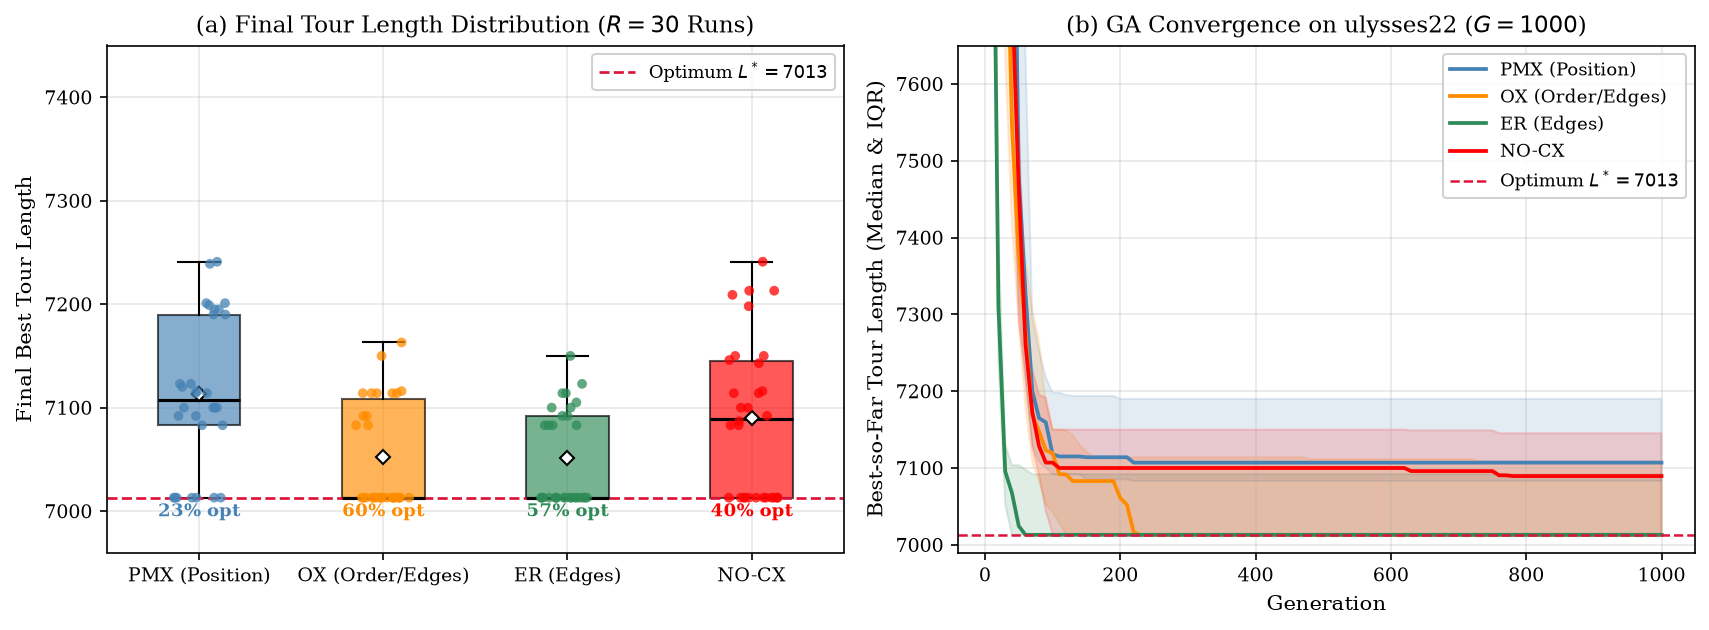

Figure 2 generated and saved to figures/fig2_ulysses22_performance.pdf (.png)


In [10]:
# Figure 2: Final Distance Boxplots & Convergence Dynamics

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))

# Panel (a): Boxplot + Jittered Runs
ax0 = axes[0]
data_boxes = [df_runs[df_runs["operator"] == op]["final_best"].values for op in OPERATOR_ORDER]
bp = ax0.boxplot(data_boxes, patch_artist=True, tick_labels=[OPERATOR_LABELS[op] for op in OPERATOR_ORDER],
                 medianprops=dict(color="black", linewidth=1.5), showmeans=True,
                 meanprops=dict(marker="D", markeredgecolor="black", markerfacecolor="white", markersize=5))

for patch, op in zip(bp["boxes"], OPERATOR_ORDER):
    patch.set_facecolor(OPERATOR_COLORS[op])
    patch.set_alpha(0.65)

rng = np.random.default_rng(42)
for i, op in enumerate(OPERATOR_ORDER):
    vals = df_runs[df_runs["operator"] == op]["final_best"].values
    jitter = rng.uniform(-0.15, 0.15, size=len(vals))
    ax0.scatter(np.full_like(vals, i + 1) + jitter, vals, color=OPERATOR_COLORS[op],
                alpha=0.75, s=22, edgecolors="none", zorder=3)
    opt_rate = (vals == OPT_DIST).mean() * 100
    ax0.text(i + 1, 6995, f"{opt_rate:.0f}% opt",
         ha="center", fontsize=8.5, weight="bold",
         color=OPERATOR_COLORS[op])
ax0.axhline(OPT_DIST, color="crimson", linestyle="--", linewidth=1.3, label=f"Optimum $L^*={OPT_DIST}$")
ax0.set_ylabel("Final Best Tour Length")
ax0.set_title("(a) Final Tour Length Distribution ($R=30$ Runs)")
ax0.set_ylim(6960, 7450)
ax0.legend(loc="upper right", framealpha=0.9)

# Panel (b): Convergence Dynamics
ax1 = axes[1]
for op in OPERATOR_ORDER:
    sub = df_history[df_history["operator"] == op]
    grp = sub.groupby("gen")["best_length"]
    gens = grp.median().index.values
    meds = grp.median().values
    q25 = grp.quantile(0.25).values
    q75 = grp.quantile(0.75).values
    ax1.plot(gens, meds, color=OPERATOR_COLORS[op], linewidth=1.8, label=OPERATOR_LABELS[op])
    ax1.fill_between(gens, q25, q75, color=OPERATOR_COLORS[op], alpha=0.15)

ax1.axhline(OPT_DIST, color="crimson", linestyle="--", linewidth=1.2, label=f"Optimum $L^*={OPT_DIST}$")
ax1.set_xlabel("Generation")
ax1.set_ylabel("Best-so-Far Tour Length (Median & IQR)")
ax1.set_title("(b) GA Convergence on ulysses22 ($G=1000$)")
ax1.set_ylim(6990, 7650)
ax1.legend(loc="upper right", framealpha=0.9)

plt.tight_layout()
fig2_path_pdf = os.path.join(FIGURES_DIR, "fig2_ulysses22_performance.pdf")
fig2_path_png = os.path.join(FIGURES_DIR, "fig2_ulysses22_performance.png")
fig.savefig(fig2_path_pdf)
fig.savefig(fig2_path_png)
plt.show()
print("Figure 2 generated and saved to figures/fig2_ulysses22_performance.pdf (.png)")


### 10. Experiment 2: Mechanistic Analysis — Edge Heritability and Population Diversity

To investigate the mechanisms behind the performance differences between PMX, OX, and ER, we examine two measurements recorded during the main GA experiment.

1. **Dynamic Edge Heritability (Panel a):** Measures the proportion of offspring edges inherited from at least one parent. The recorded value is the rolling mean of the last 50 crossover events at each checkpoint. Higher values indicate stronger preservation of parental edges.

2. **Population Edge Diversity (Panel b):** Measures the number of unique undirected edges in the population, normalized by the number of cities. Higher values indicate greater variation in the population's edge combinations.

Both measurements are recorded every 10 generations and summarised across the 30 independent runs for each configuration. The shaded regions represent the interquartile range (25th–75th percentile).

**Mechanistic Analysis:**

The two panels allow us to examine the relationship between parental edge preservation and population diversity during evolution. We investigate whether differences in edge heritability are associated with differences in population diversity and final solution quality.

The NO-CX baseline is included in the population diversity analysis. However, edge heritability is not applicable to NO-CX because crossover is disabled and no crossover events occur.

This analysis helps assess whether preserving parental edges may influence the balance between exploiting existing solutions and maintaining sufficient population variation.

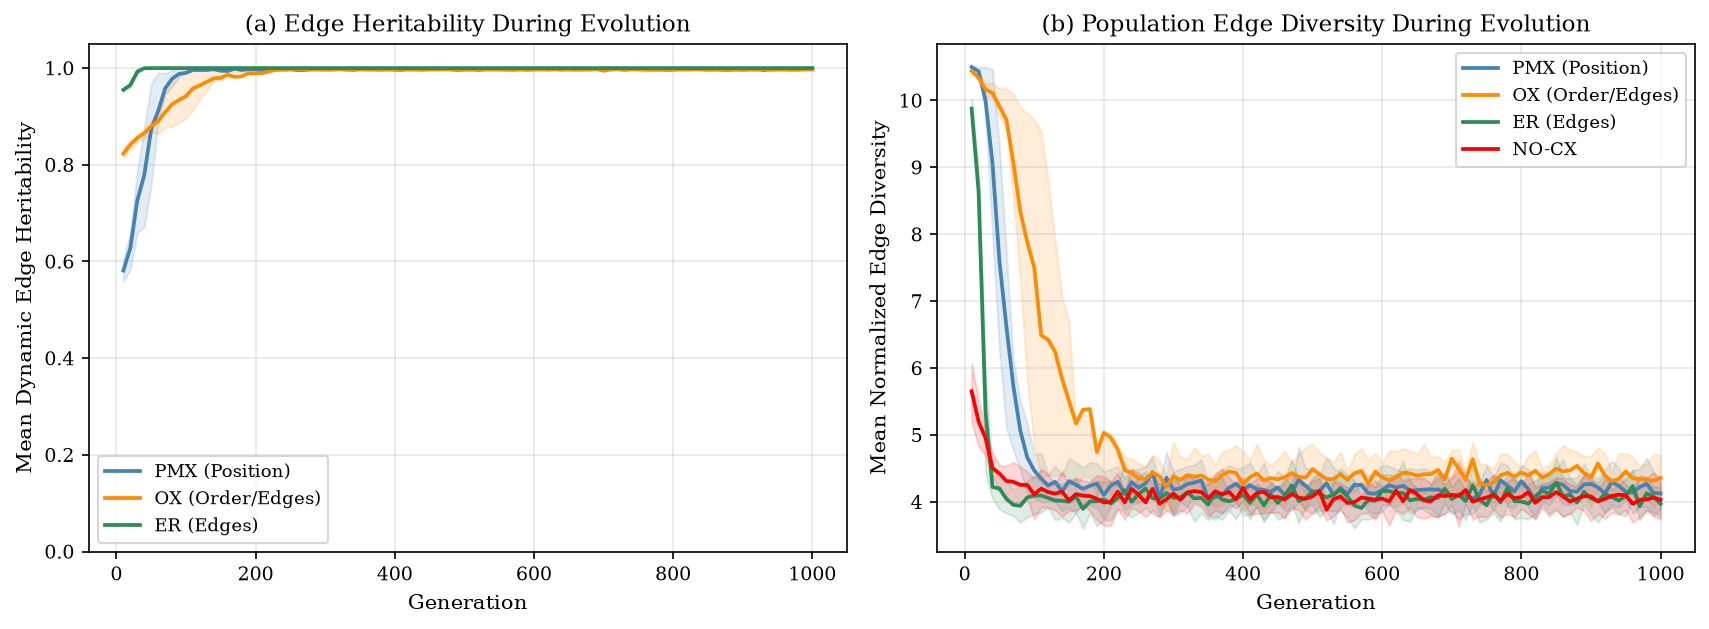

Figure 3 generated and saved.


In [11]:
# Figure 3: Edge Heritability and Population Diversity

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))

# Panel (a): Dynamic Edge Heritability
ax0 = axes[0]

CROSSOVER_ORDER = ["PMX", "OX", "ER"]

for op in CROSSOVER_ORDER:
    sub = df_history[df_history["operator"] == op]
    grp = sub.groupby("gen")["edge_heritability"]

    gens = grp.mean().index.to_numpy()
    means = grp.mean().to_numpy()
    q25 = grp.quantile(0.25).to_numpy()
    q75 = grp.quantile(0.75).to_numpy()

    ax0.plot(
        gens, means,
        color=OPERATOR_COLORS[op],
        linewidth=1.8,
        label=OPERATOR_LABELS[op]
    )

    ax0.fill_between(
        gens, q25, q75,
        color=OPERATOR_COLORS[op],
        alpha=0.15
    )

ax0.set_xlabel("Generation")
ax0.set_ylabel("Mean Dynamic Edge Heritability")
ax0.set_title("(a) Edge Heritability During Evolution")
ax0.set_ylim(0, 1.05)
ax0.legend(loc="best")


# Panel (b): Population Edge Diversity
ax1 = axes[1]

for op in EXPERIMENT_ORDER:
    sub = df_history[df_history["operator"] == op]
    grp = sub.groupby("gen")["edge_diversity"]

    gens = grp.mean().index.to_numpy()
    means = grp.mean().to_numpy()
    q25 = grp.quantile(0.25).to_numpy()
    q75 = grp.quantile(0.75).to_numpy()

    ax1.plot(
        gens, means,
        color=OPERATOR_COLORS[op],
        linewidth=1.8,
        label=OPERATOR_LABELS[op]
    )

    ax1.fill_between(
        gens, q25, q75,
        color=OPERATOR_COLORS[op],
        alpha=0.15
    )

ax1.set_xlabel("Generation")
ax1.set_ylabel("Mean Normalized Edge Diversity")
ax1.set_title("(b) Population Edge Diversity During Evolution")
ax1.legend(loc="best")

plt.tight_layout()

fig3_path_pdf = os.path.join(FIGURES_DIR, "fig3_mechanism_dynamics.pdf")
fig3_path_png = os.path.join(FIGURES_DIR, "fig3_mechanism_dynamics.png")

fig.savefig(fig3_path_pdf)
fig.savefig(fig3_path_png)
plt.show()

print("Figure 3 generated and saved.")

### 11. Figure 4: Geographical Tour Visualisation on ulysses22

Figure 4 compares two geographical TSP solutions using the coordinates of the 22 cities.

- **Optimal Tour (L = 7013):** Visualises the globally optimal route for the ulysses22 instance.
- **Illustrative Suboptimal Tour:** Shows a valid tour with a longer total distance than the known optimum, providing a visual comparison of a non-optimal route.

The comparison provides a geographical interpretation of how different edge combinations affect the overall tour length and route structure.

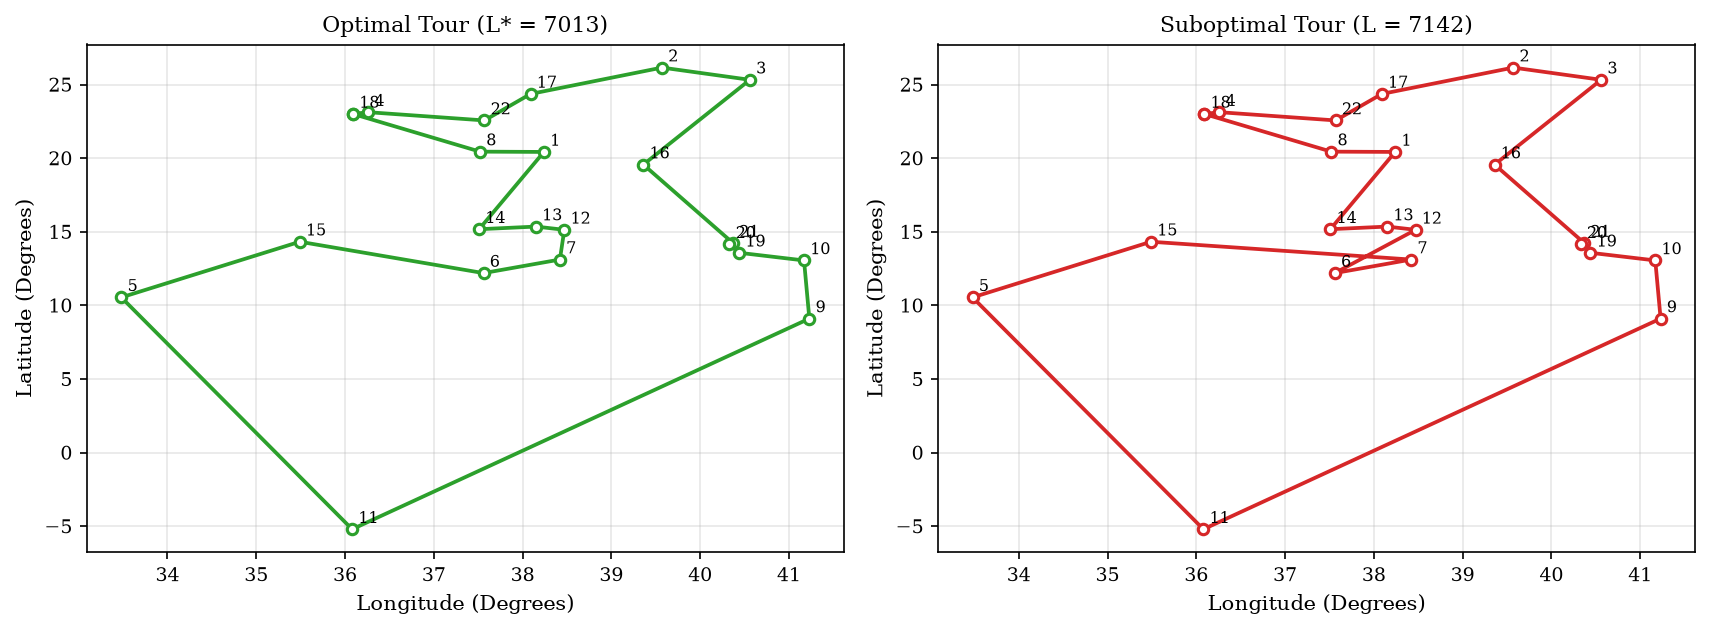

Figure 4 generated and saved.


In [12]:
# Figure 4: Geographic Tour Visualisation (ulysses22)

# Known optimal tour (0-indexed)
opt_tour = [17, 3, 21, 16, 1, 2, 15, 20, 19, 18, 9, 8, 10, 4, 14, 5, 6, 11, 12, 13, 0, 7]

assert evaluate_tour(opt_tour, dist_matrix) == 7013

# Representative suboptimal tour
sub_tour = [17, 3, 21, 16, 1, 2, 15, 20, 19, 18, 9, 8, 10, 4, 14, 6, 5, 11, 12, 13, 0, 7]
sub_len = evaluate_tour(sub_tour, dist_matrix)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11.5, 4.3))

for ax, tour, title, col in [
    (ax_a, opt_tour, "Optimal Tour (L* = 7013)", "#2ca02c"),
    (ax_b, sub_tour, f"Suboptimal Tour (L = {sub_len})", "#d62728"),
]:
    x_c = [coords[u][0] for u in tour] + [coords[tour[0]][0]]
    y_c = [coords[u][1] for u in tour] + [coords[tour[0]][1]]

    ax.plot(
        x_c, y_c, "-o",
        color=col, linewidth=1.8, markersize=5,
        mfc="white", mec=col, mew=1.5
    )

    for u in tour:
        ax.annotate(
            str(nodes[u]),
            (coords[u][0], coords[u][1]),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=7.5
        )

    ax.set_title(title, fontsize=10.5)
    ax.set_xlabel("Longitude (Degrees)")
    ax.set_ylabel("Latitude (Degrees)")

plt.tight_layout()

fig4_path_pdf = os.path.join(FIGURES_DIR, "fig4_ulysses22_tours.pdf")
fig4_path_png = os.path.join(FIGURES_DIR, "fig4_ulysses22_tours.png")

fig.savefig(fig4_path_pdf)
fig.savefig(fig4_path_png)
plt.show()

print("Figure 4 generated and saved.")

In [13]:
for op in EXPERIMENT_ORDER:
    sub = df_history[df_history["operator"] == op]

    print(f"\n{op}")

    if op != "NO-CX":
        print("Mean edge heritability:",
              sub["edge_heritability"].mean())
    else:
        print("Mean edge heritability: N/A (crossover disabled)")

    print("Mean edge diversity:",
          sub["edge_diversity"].mean())

    print("Initial edge diversity:",
          sub.groupby("gen")["edge_diversity"].mean().iloc[0])

    print("Final edge diversity:",
          sub.groupby("gen")["edge_diversity"].mean().iloc[-1])


PMX
Mean edge heritability: 0.9819721212121212
Mean edge diversity: 4.522242424242424
Initial edge diversity: 10.5
Final edge diversity: 4.124242424242424

OX
Mean edge heritability: 0.983985303030303
Mean edge diversity: 5.020666666666667
Initial edge diversity: 10.440909090909091
Final edge diversity: 4.357575757575757

ER
Mean edge heritability: 0.9991222727272726
Mean edge diversity: 4.185712121212121
Initial edge diversity: 9.877272727272727
Final edge diversity: 3.9696969696969697

NO-CX
Mean edge heritability: N/A (crossover disabled)
Mean edge diversity: 4.127151515151516
Initial edge diversity: 5.653030303030303
Final edge diversity: 4.03030303030303


In [14]:
for op in EXPERIMENT_ORDER:
    sub = df_history[df_history["operator"] == op]
    print(f"\n{op}")

    for gen in [10, 100, 200, 400, 600, 800, 1000]:
        values = sub[sub["gen"] == gen]["edge_diversity"]
        print(f"Generation {gen}: {values.mean():.4f}")


PMX
Generation 10: 10.5000
Generation 100: 4.4682
Generation 200: 4.1030
Generation 400: 4.1788
Generation 600: 4.1742
Generation 800: 4.3076
Generation 1000: 4.1242

OX
Generation 10: 10.4409
Generation 100: 7.5030
Generation 200: 5.0333
Generation 400: 4.2697
Generation 600: 4.3667
Generation 800: 4.4394
Generation 1000: 4.3576

ER
Generation 10: 9.8773
Generation 100: 4.0924
Generation 200: 4.0364
Generation 400: 4.1091
Generation 600: 4.1636
Generation 800: 4.0030
Generation 1000: 3.9697

NO-CX
Generation 10: 5.6530
Generation 100: 4.1121
Generation 200: 3.9894
Generation 400: 4.2076
Generation 600: 4.0500
Generation 800: 4.0712
Generation 1000: 4.0303


### 12. Scientific Discussion, Key Takeaways, and Limitations

#### 1. What Did the Experiments Find?

The main experiment compared three crossover operators (PMX, OX and ER) and a NO-CX baseline control using 30 matched random seeds per configuration, resulting in 120 GA executions.

The final tour-length results showed clear differences between the configurations:

- **OX:** Achieved a median final tour length of 7013 and a mean of 7052.77 (SD = 51.77). It reached the global optimum in 60% of runs (18 out of 30).
- **ER:** Achieved a median of 7013 and a mean of 7051.43 (SD = 46.48). It reached the global optimum in 56.67% of runs (17 out of 30). ER had the lowest observed standard deviation among the four configurations.
- **PMX:** Achieved a median of 7107 and a mean of 7113.40 (SD = 72.89). It reached the global optimum in 23.33% of runs (7 out of 30).
- **NO-CX:** Achieved a median of 7089.5 and a mean of 7090.27 (SD = 75.50). It reached the global optimum in 40% of runs (12 out of 30).

The Friedman test detected a statistically significant difference across the four configurations (χ² = 18.3024, df = 3, p = 0.000381).

Pairwise Wilcoxon signed-rank tests with Holm correction showed that:

- OX significantly outperformed PMX (adjusted p = 0.0341).
- ER significantly outperformed PMX (adjusted p = 0.0034).
- ER significantly outperformed NO-CX (adjusted p = 0.0345).
- No statistically significant difference was detected between PMX and NO-CX (adjusted p = 0.4172).
- No statistically significant difference was detected between OX and ER (adjusted p = 0.7932).
- No statistically significant difference was detected between OX and NO-CX (adjusted p = 0.1199).

These results indicate that OX and ER performed better than PMX. ER also demonstrated a statistically significant improvement over the NO-CX baseline. However, the results do not establish a statistically significant difference between OX and ER.

#### 2. Edge Heritability and Population Diversity

The mechanistic analysis examined how parental edge preservation and population edge diversity changed during evolution.

ER achieved the highest mean dynamic edge heritability (0.9991), compared with OX (0.9840) and PMX (0.9820). This indicates that ER preserved a larger proportion of parental edges during crossover.

Edge heritability is not applicable to NO-CX because crossover is disabled in this configuration.

However, higher edge heritability did not correspond to higher population diversity.

OX maintained the highest mean population edge diversity (5.0207), followed by PMX (4.5222), ER (4.1857) and NO-CX (4.1272).

The differences were particularly clear during the early stages of evolution. At generation 100, OX retained an average edge diversity of 7.5030, compared with 4.4682 for PMX, 4.0924 for ER and 4.1121 for NO-CX. OX therefore maintained considerably more population diversity during this stage.

By generation 1000, the differences had become smaller. OX retained a diversity of 4.3576, PMX 4.1242, ER 3.9697 and NO-CX 4.0303.

These observations suggest that OX maintained greater population diversity during much of the evolution process, whereas ER preserved parental edges more strongly but maintained lower diversity.

The NO-CX control also showed relatively low diversity at generation 10 (5.6530), compared with the crossover configurations, which ranged from 9.8773 to 10.5000. This indicates that the configurations developed different diversity levels during the first ten generations.

These patterns provide possible explanations for the optimisation results. OX may benefit from maintaining greater population variation, while ER may benefit from stronger preservation of useful parental edges. The NO-CX results also suggest that crossover contributes to the population's evolutionary behaviour, although its effect depends on the operator.

However, these measurements establish associations rather than causation. The experiment does not prove that higher diversity or edge heritability directly causes better optimisation performance.

#### 3. Why Did PMX Perform Worse?

PMX produced higher final tour lengths and a lower optimal success rate than OX and ER.

One possible explanation is that preserving positions does not directly guarantee the preservation of useful adjacencies in a cyclic TSP representation. This may result in offspring with less favourable edge combinations.

The mechanistic results also show that PMX had lower mean edge heritability than ER and maintained less population diversity than OX.

However, the current experiment does not isolate these mechanisms through separate controlled experiments. Therefore, these explanations should be treated as possible interpretations rather than proven causes.

#### 4. What Does the NO-CX Baseline Tell Us?

The NO-CX configuration provides a baseline for evaluating the contribution of crossover.

It achieved a 40% optimal success rate, which was higher than PMX's 23.33% but lower than OX's 60% and ER's 56.67%.

The statistical comparisons showed that ER significantly outperformed NO-CX. However, the differences between OX and NO-CX, and between PMX and NO-CX, were not statistically significant after Holm correction.

This suggests that the contribution of crossover depends on the operator used. Disabling crossover did not produce significantly worse results than every crossover configuration.

The NO-CX results therefore do not support the conclusion that simply enabling crossover always improves optimisation performance. Instead, the choice of crossover operator appears to matter.

#### 5. Study Limitations

- **Problem Scale:** The experiment used a single small TSPLIB instance, ulysses22, containing 22 cities. The findings cannot automatically be generalised to larger or structurally different TSP instances.

- **Fixed Hyperparameters:** Population size (N = 200), mutation probability (p_m = 0.2), crossover probability (p_c = 0.9) and tournament size (k = 3) were held constant. Different parameter settings may produce different performance and diversity patterns.

- **Limited Operator Selection:** Only three crossover operators were evaluated: PMX, OX and ER. Other crossover methods may produce different results.

- **No Local Search:** The GA did not incorporate local search methods such as 2-opt or Lin-Kernighan. Combining crossover with local search could change the relative performance of the configurations.

- **Stochastic Variation:** Although 30 matched runs were used, the results remain subject to randomness. A larger number of runs and additional TSP instances would provide stronger evidence about general performance.

- **Mechanistic Measurements:** Edge heritability and population edge diversity provide useful information about the evolutionary process, but they do not independently establish why one configuration performs better than another.

#### 6. Conclusion

The results show that OX and ER outperformed PMX on the ulysses22 instance under the tested GA configuration. Both operators achieved higher optimal success rates, and their advantages over PMX were statistically significant.

ER also significantly outperformed the NO-CX baseline, demonstrating that an edge-based crossover can provide an improvement over selection, mutation and elitism without crossover. However, OX did not significantly outperform NO-CX after multiple-comparison correction.

No statistically significant difference was detected between OX and ER. Therefore, the experiment does not establish that either operator is generally superior to the other.

The mechanistic measurements provide further insight into their behaviour. ER achieved the highest edge heritability, while OX maintained the highest population edge diversity. This suggests that preserving parental edges and maintaining population diversity are distinct properties of crossover operators.

Overall, the findings suggest that preserving useful parental edges is important, but edge heritability alone is insufficient to explain optimisation performance. Population diversity and the interaction between crossover and the other GA components must also be considered when evaluating the effectiveness of a crossover operator.